# U-Net reproduction (Table 2) — Colab T4
Runtime → Change runtime type → **T4 GPU**, then Run all.

In [ ]:
!nvidia-smi -L
!pip -q install tifffile imagecodecs

GPU 0: Tesla T4 (UUID: GPU-26485bad-eaa7-c28a-de24-34d9a5caa034)


In [ ]:
%%writefile unet.py
"""U-Net (Ronneberger, Fischer, Brox 2015) in PyTorch.

Faithful to the paper's Fig. 1:
  * unpadded 3x3 convs + ReLU (so the output is smaller than the input),
  * 2x2 max-pool, channels doubled at each down step,
  * 2x2 up-convolution (transposed conv, stride 2) halving channels,
  * copy-and-crop skip connections (centre-crop contracting features, concat),
  * dropout at the end of the contracting path,
  * final 1x1 conv to n_classes,
  * He initialisation with std = sqrt(2/N), N = incoming nodes of a neuron.
With the defaults: 572x572 input -> 388x388 output, 23 conv layers (19 conv + 4 up-conv).
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def _block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3), nn.ReLU(inplace=True),
    )


def _crop_like(x, ref):
    dh, dw = x.shape[2] - ref.shape[2], x.shape[3] - ref.shape[3]
    return x[:, :, dh // 2: dh // 2 + ref.shape[2], dw // 2: dw // 2 + ref.shape[3]]


def valid_output_size(inp, depth=4):
    """Output size for a given input size; raises if a max-pool would see an odd size."""
    s = inp
    for _ in range(depth):
        s -= 4
        if s % 2:
            raise ValueError(f"input {inp}: odd feature size {s} before 2x2 max-pool")
        s //= 2
    s -= 4
    for _ in range(depth):
        s = s * 2 - 4
    return s


class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64, depth=4, dropout=0.5):
        super().__init__()
        self.depth = depth
        chans = [base * 2 ** i for i in range(depth + 1)]  # 64,128,256,512,1024
        self.enc = nn.ModuleList()
        c = in_ch
        for i in range(depth):
            self.enc.append(_block(c, chans[i]))
            c = chans[i]
        self.bottom = _block(chans[depth - 1], chans[depth])
        self.drop = nn.Dropout2d(dropout)
        self.ups, self.dec = nn.ModuleList(), nn.ModuleList()
        for i in reversed(range(depth)):
            self.ups.append(nn.ConvTranspose2d(chans[i + 1], chans[i], 2, stride=2))
            self.dec.append(_block(chans[i] * 2, chans[i]))
        self.head = nn.Conv2d(chans[0], n_classes, 1)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.in_channels * m.kernel_size[0] * m.kernel_size[1]
                nn.init.normal_(m.weight, 0.0, math.sqrt(2.0 / n))
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.ConvTranspose2d):
                # stride-2, kernel-2 transposed conv: each output pixel sees in_channels inputs
                nn.init.normal_(m.weight, 0.0, math.sqrt(2.0 / m.in_channels))
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x)
            skips.append(x)
            if i == self.depth - 1:
                x = self.drop(x)           # dropout at end of contracting path
            x = F.max_pool2d(x, 2)
        x = self.drop(self.bottom(x))
        for up, blk, skip in zip(self.ups, self.dec, reversed(skips)):
            x = up(x)
            x = torch.cat([_crop_like(skip, x), x], dim=1)
            x = blk(x)
        return self.head(x)


def count_conv_layers(model):
    return sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())


Overwriting unet.py


In [ ]:
%%writefile data.py
"""Data pipeline for U-Net on Cell Tracking Challenge data.

Implements the paper's training ingredients:
  * 1-px separation borders between touching cells (Sec. 1 / Fig. 3c)
  * pixel-wise weight map  w = w_c + w0 * exp(-(d1+d2)^2 / (2 sigma^2))   (Eq. 2)
  * random elastic deformation: 3x3 coarse grid, displacements ~ N(0, 10 px),
    bicubic interpolation (Sec. 3.1), plus flips/rot90 and gray-value jitter
  * overlap-tile inference with mirror extrapolation (Fig. 2)
  * the challenge's SEG (Jaccard) measure used for "IOU" in Table 2
"""
import glob
import math
import os
import random
import re
import urllib.request
import zipfile

import numpy as np
import scipy.ndimage as ndi
import torch
import torch.nn.functional as F

CTC_URL = "http://data.celltrackingchallenge.net/training-datasets/{}.zip"


# ----------------------------------------------------------------- loading
def download_ctc(name, root):
    out = os.path.join(root, name)
    if os.path.isdir(out):
        return out
    os.makedirs(root, exist_ok=True)
    zp = os.path.join(root, name + ".zip")
    print("downloading", CTC_URL.format(name))
    urllib.request.urlretrieve(CTC_URL.format(name), zp)
    with zipfile.ZipFile(zp) as z:
        z.extractall(root)
    return out


def normalize(img):
    lo, hi = np.percentile(img, (1, 99))
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1).astype(np.float32)


def load_ctc(path, seqs=("01", "02")):
    """Load gold-truth (man_seg) annotated frames: list of dict(name, img, lab)."""
    import tifffile
    items = []
    for s in seqs:
        for f in sorted(glob.glob(os.path.join(path, f"{s}_GT", "SEG", "man_seg*.tif"))):
            idx = re.findall(r"(\d+)", os.path.basename(f))[-1]
            imgf = os.path.join(path, s, f"t{idx}.tif")
            if not os.path.exists(imgf):
                continue
            img = tifffile.imread(imgf).astype(np.float32)
            lab = tifffile.imread(f).astype(np.int32)
            items.append(dict(name=f"{s}_{idx}", img=normalize(img), lab=lab))
    return items


# ----------------------------------------------------------------- targets
def make_targets(lab, w0=10.0, sigma=5.0):
    """Binary mask with 1-px borders between touching cells + weight map (Eq. 2)."""
    lab = lab.astype(np.int32)
    mx = ndi.maximum_filter(lab, size=3)
    border = (lab > 0) & (mx > lab)         # pixel next to a different, higher-id cell
    lab2 = lab.copy()
    lab2[border] = 0
    mask = (lab2 > 0).astype(np.int64)

    # w_c: balance class frequencies (expected weight ~1)
    p = float(np.clip(mask.mean(), 1e-3, 1 - 1e-3))
    wc = np.where(mask == 1, 0.5 / p, 0.5 / (1 - p)).astype(np.float32)

    ids = np.unique(lab2)
    ids = ids[ids > 0]
    if len(ids) >= 2:
        d = np.stack([ndi.distance_transform_edt(lab2 != i) for i in ids]).astype(np.float32)
        d = np.partition(d, 1, axis=0)[:2]
        d1, d2 = d.min(0), d.max(0)
        w = wc + w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
    else:
        w = wc
    return mask, w.astype(np.float32)


# ----------------------------------------------------------------- augmentation
def elastic_deform(img, mask, wgt, sigma=10.0, grid=3):
    """Same random smooth deformation for image (bicubic), weights (bilinear), mask (nearest)."""
    dev = img.device
    _, _, H, W = img.shape
    disp = torch.randn(1, 2, grid, grid, device=dev) * sigma
    disp = F.interpolate(disp, size=(H, W), mode="bicubic", align_corners=True)
    flow = disp.permute(0, 2, 3, 1).clone()
    flow[..., 0] *= 2.0 / (W - 1)
    flow[..., 1] *= 2.0 / (H - 1)
    theta = torch.tensor([[[1, 0, 0], [0, 1, 0]]], dtype=torch.float32, device=dev)
    g = F.affine_grid(theta, (1, 1, H, W), align_corners=True) + flow
    kw = dict(padding_mode="reflection", align_corners=True)
    img = F.grid_sample(img, g, mode="bicubic", **kw)
    wgt = F.grid_sample(wgt, g, mode="bilinear", **kw)
    mask = F.grid_sample(mask, g, mode="nearest", **kw)
    return img, mask, wgt


class TileSampler:
    """Samples (input tile 572x572, target 388x388, weights 388x388) from mirror-padded images."""

    def __init__(self, items, tile=572, out=388, w0=10.0, sigma=5.0):
        self.tile, self.out = tile, out
        self.pad = (tile - out) // 2
        self.data = []
        for it in items:
            mask, w = make_targets(it["lab"], w0, sigma)
            p = self.pad
            self.data.append((np.pad(it["img"], p, "reflect"),
                              np.pad(mask, p, "reflect").astype(np.float32),
                              np.pad(w, p, "reflect")))

    def sample(self, device, elastic=True, use_weight=True):
        T, c = self.tile, self.pad
        img, mask, w = random.choice(self.data)
        H, W = img.shape
        y, x = random.randint(0, H - T), random.randint(0, W - T)
        t = lambda a: torch.from_numpy(np.ascontiguousarray(a[y:y + T, x:x + T]))[None, None].to(device)
        img, mask, w = t(img), t(mask), t(w)
        if elastic:
            img, mask, w = elastic_deform(img, mask, w)
        k = random.randint(0, 3)
        flip = random.random() < 0.5
        def geo(a):
            a = torch.rot90(a, k, (2, 3))
            return torch.flip(a, (3,)) if flip else a
        img, mask, w = geo(img), geo(mask), geo(w)
        img = img * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1)   # gray-value variation
        mask = mask[:, 0, c:-c, c:-c].round().long()
        w = w[:, 0, c:-c, c:-c]
        if not use_weight:
            w = torch.ones_like(w)
        return img, mask, w


# ----------------------------------------------------------------- inference
@torch.no_grad()
def predict_full(model, img, device, tile=572, out=388, amp=True, tta=False):
    """Overlap-tile strategy: mirror-extrapolate borders, stitch 388x388 outputs."""
    model.eval()
    H, W = img.shape
    pad = (tile - out) // 2
    nH, nW = math.ceil(H / out), math.ceil(W / out)
    padded = np.pad(img, ((pad, nH * out + pad - H), (pad, nW * out + pad - W)), mode="reflect")
    prob = np.zeros((nH * out, nW * out), np.float32)
    variants = [(k, f) for k in range(4) for f in (False, True)] if tta else [(0, False)]
    for i in range(nH):
        for j in range(nW):
            t = torch.from_numpy(padded[i * out:i * out + tile, j * out:j * out + tile].copy())[None, None].to(device)
            acc = 0
            for k, f in variants:
                x = torch.rot90(t, k, (2, 3))
                x = torch.flip(x, (3,)) if f else x
                with torch.autocast(device_type=device.type, enabled=amp):
                    p = torch.softmax(model(x).float(), 1)[:, 1:2]
                p = torch.flip(p, (3,)) if f else p
                acc = acc + torch.rot90(p, -k, (2, 3))
            prob[i * out:(i + 1) * out, j * out:(j + 1) * out] = (acc / len(variants))[0, 0].cpu().numpy()
    return prob[:H, :W]


# ----------------------------------------------------------------- metrics
def instances_from_prob(prob, thr=0.5, min_size=50):
    lab, n = ndi.label(prob > thr)
    if n:
        sizes = ndi.sum(np.ones_like(lab), lab, range(1, n + 1))
        for i, s in enumerate(sizes, 1):
            if s < min_size:
                lab[lab == i] = 0
    return lab


def seg_score(pred_lab, gt_lab):
    """Cell-Tracking-Challenge SEG: mean Jaccard of GT objects matched with |R∩S|/|R|>0.5."""
    ids = np.unique(gt_lab)
    ids = ids[ids > 0]
    scores = []
    for g in ids:
        gm = gt_lab == g
        ov = pred_lab[gm]
        ov = ov[ov > 0]
        if ov.size == 0:
            scores.append(0.0)
            continue
        pm = pred_lab == np.bincount(ov).argmax()
        inter = (gm & pm).sum()
        scores.append(inter / (gm | pm).sum() if inter / gm.sum() > 0.5 else 0.0)
    return float(np.mean(scores)) if scores else float("nan")


def fg_iou(prob, gt_lab, thr=0.5):
    p, g = prob > thr, gt_lab > 0
    return float((p & g).sum() / max((p | g).sum(), 1))


Overwriting data.py


In [ ]:
%%writefile train.py
"""Train / evaluate U-Net on a Cell Tracking Challenge 2D dataset (paper's Table 2).

Example (Colab T4):
    python train.py --dataset PhC-C2DH-U373 --iters 6000
    python train.py --dataset DIC-C2DH-HeLa --iters 6000
Ablations:  --no_elastic   --no_weight
"""
import argparse
import json
import os
import random
import time

import numpy as np
import torch
import torch.nn.functional as F

from data import (TileSampler, download_ctc, fg_iou, instances_from_prob, load_ctc,
                  predict_full, seg_score)
from unet import UNet, count_conv_layers, valid_output_size


def evaluate(model, items, device, amp, tta):
    segs, ious, probs = [], [], []
    for it in items:
        prob = predict_full(model, it["img"], device, amp=amp, tta=tta)
        segs.append(seg_score(instances_from_prob(prob), it["lab"]))
        ious.append(fg_iou(prob, it["lab"]))
        probs.append(prob)
    return float(np.nanmean(segs)), float(np.mean(ious)), probs


def save_figure(items, probs, path, n=3):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    n = min(n, len(items))
    fig, ax = plt.subplots(n, 3, figsize=(9, 3 * n), squeeze=False)
    for r in range(n):
        ax[r, 0].imshow(items[r]["img"], cmap="gray"); ax[r, 0].set_title("input")
        ax[r, 1].imshow(items[r]["img"], cmap="gray")
        ax[r, 1].contour(items[r]["lab"] > 0, [0.5], colors="yellow", linewidths=1); ax[r, 1].set_title("ground truth")
        ax[r, 2].imshow(items[r]["img"], cmap="gray")
        ax[r, 2].imshow(np.ma.masked_less(probs[r], 0.5), alpha=0.5, cmap="cool")
        ax[r, 2].contour(items[r]["lab"] > 0, [0.5], colors="yellow", linewidths=0.8); ax[r, 2].set_title("u-net (cyan) vs GT (yellow)")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.close()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", default="PhC-C2DH-U373")
    ap.add_argument("--data_root", default="data")
    ap.add_argument("--out", default="results")
    ap.add_argument("--iters", type=int, default=6000)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--momentum", type=float, default=0.99)
    ap.add_argument("--base", type=int, default=64, help="channels of first block (paper: 64)")
    ap.add_argument("--split", choices=["seq", "random"], default="seq",
                    help="seq: train on sequence 01, test on 02; random: 80/20 over frames")
    ap.add_argument("--eval_every", type=int, default=1000)
    ap.add_argument("--no_elastic", action="store_true")
    ap.add_argument("--no_weight", action="store_true")
    ap.add_argument("--no_amp", action="store_true")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--tag", default="")
    a = ap.parse_args()

    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = (dev.type == "cuda") and not a.no_amp
    os.makedirs(a.out, exist_ok=True)
    name = a.dataset + (f"_{a.tag}" if a.tag else "")

    path = download_ctc(a.dataset, a.data_root)
    items = load_ctc(path)
    train = [i for i in items if i["name"].startswith("01")]
    test = [i for i in items if i["name"].startswith("02")]
    if a.split == "random" or not train or not test:
        rng = random.Random(a.seed)
        idx = list(range(len(items))); rng.shuffle(idx)
        k = max(1, int(0.2 * len(items)))
        test = [items[i] for i in idx[:k]]; train = [items[i] for i in idx[k:]]
        a.split = "random"
    print(f"annotated frames: {len(items)} | train {len(train)} | test {len(test)} | split={a.split}")

    model = UNet(1, 2, base=a.base).to(dev)
    print(f"conv layers: {count_conv_layers(model)} (paper: 23) | 572->{valid_output_size(572)} | "
          f"params {sum(p.numel() for p in model.parameters())/1e6:.1f}M | device {dev} amp={amp}")

    sampler = TileSampler(train)
    opt = torch.optim.SGD(model.parameters(), lr=a.lr, momentum=a.momentum)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, [int(0.7 * a.iters)], 0.1)
    scaler = torch.amp.GradScaler(dev.type, enabled=amp)

    log, t0, run = [], time.time(), 0.0
    for it in range(1, a.iters + 1):
        model.train()
        x, y, w = sampler.sample(dev, elastic=not a.no_elastic, use_weight=not a.no_weight)
        with torch.autocast(device_type=dev.type, enabled=amp):
            logits = model(x)
        loss = (F.cross_entropy(logits.float(), y, reduction="none") * w).mean()   # weighted CE, Eq. (1)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        scaler.step(opt); scaler.update(); sched.step()
        run = 0.98 * run + 0.02 * loss.item() if it > 1 else loss.item()
        if it % 100 == 0:
            log.append((it, run))
        if it % a.eval_every == 0 or it == a.iters:
            seg, iou, _ = evaluate(model, test, dev, amp, tta=False)
            print(f"it {it:5d} | loss {run:.4f} | test SEG {seg:.4f} | fg-IoU {iou:.4f} | {time.time()-t0:.0f}s")

    seg, iou, probs = evaluate(model, test, dev, amp, tta=True)
    print(f"FINAL (8-fold flip/rot TTA) test SEG(IOU) {seg:.4f} | fg-IoU {iou:.4f}")
    res = dict(dataset=a.dataset, tag=a.tag, seg=seg, fg_iou=iou, iters=a.iters, base=a.base,
               split=a.split, n_train=len(train), n_test=len(test), elastic=not a.no_elastic,
               weight_map=not a.no_weight, train_seconds=time.time() - t0, loss_log=log)
    json.dump(res, open(os.path.join(a.out, name + ".json"), "w"), indent=1)
    torch.save(model.state_dict(), os.path.join(a.out, name + ".pt"))
    save_figure(test, probs, os.path.join(a.out, name + "_qualitative.png"))


if __name__ == "__main__":
    main()


Overwriting train.py


In [ ]:
%%writefile make_table.py
"""Collect results/*.json into a markdown table next to the paper's Table 2 numbers."""
import glob
import json

PAPER = {"PhC-C2DH-U373": 0.9203, "DIC-C2DH-HeLa": 0.7756}
PAPER_2ND = {"PhC-C2DH-U373": 0.83, "DIC-C2DH-HeLa": 0.46}

rows = [json.load(open(f)) for f in sorted(glob.glob("results/*.json"))]
print("| Dataset | Variant | Iters | Base ch. | Split (train/test) | Ours SEG(IOU) | Ours fg-IoU | Paper u-net | Paper 2nd best |")
print("|---|---|---|---|---|---|---|---|---|")
for r in rows:
    variant = r["tag"] or "full (weight map + elastic)"
    print(f"| {r['dataset']} | {variant} | {r['iters']} | {r['base']} | {r['split']} ({r['n_train']}/{r['n_test']}) | "
          f"{r['seg']:.4f} | {r['fg_iou']:.4f} | {PAPER[r['dataset']]} | {PAPER_2ND[r['dataset']]} |")


Overwriting make_table.py


## Main runs (full method: weight map + elastic deformation)

In [ ]:
!python train.py --dataset PhC-C2DH-U373 --iters 6000

annotated frames: 34 | train 15 | test 19 | split=seq
conv layers: 23 (paper: 23) | 572->388 | params 31.0M | device cuda amp=True
it  1000 | loss 0.1231 | test SEG 0.6561 | fg-IoU 0.5225 | 91s
it  2000 | loss 0.0516 | test SEG 0.6792 | fg-IoU 0.5903 | 184s
it  3000 | loss 0.0397 | test SEG 0.7340 | fg-IoU 0.6948 | 279s
it  4000 | loss 0.0365 | test SEG 0.7394 | fg-IoU 0.6768 | 375s
it  5000 | loss 0.0330 | test SEG 0.7770 | fg-IoU 0.7376 | 472s
it  6000 | loss 0.0340 | test SEG 0.7675 | fg-IoU 0.7336 | 568s
FINAL (8-fold flip/rot TTA) test SEG(IOU) 0.7720 | fg-IoU 0.7361


In [ ]:
!python train.py --dataset DIC-C2DH-HeLa --iters 6000

annotated frames: 18 | train 9 | test 9 | split=seq
conv layers: 23 (paper: 23) | 572->388 | params 31.0M | device cuda amp=True
/content/train.py:107: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()
it  1000 | loss 0.5908 | test SEG 0.1425 | fg-IoU 0.8049 | 98s
it  2000 | loss 0.5837 | test SEG 0.2011 | fg-IoU 0.7349 | 194s
it  3000 | loss 0.5169 | test SEG 0.1649 | fg-IoU 0.7759 | 289s
it  4000 | loss 0.4903 | test SEG 0.1618 | fg-IoU 0.7854 | 384s
it  5000 | loss 0.4395 | test SEG 0.1786 | fg-IoU 0.7880 | 479s
it  6000 | loss 0.4029 | test SEG 0.1545 | fg-IoU 0.8200 | 575s
FINAL (8-fold flip/rot TT

## Optional ablations on PhC-U373 (extra, not in the paper)

In [ ]:
!python train.py --dataset PhC-C2DH-U373 --iters 6000 --no_elastic --tag no_elastic
!python train.py --dataset PhC-C2DH-U373 --iters 6000 --no_weight --tag no_weight

annotated frames: 34 | train 15 | test 19 | split=seq
conv layers: 23 (paper: 23) | 572->388 | params 31.0M | device cuda amp=True
it  1000 | loss 0.1027 | test SEG 0.6611 | fg-IoU 0.5710 | 96s
it  2000 | loss 0.0402 | test SEG 0.6891 | fg-IoU 0.6181 | 192s
it  3000 | loss 0.0341 | test SEG 0.6410 | fg-IoU 0.5516 | 287s
it  4000 | loss 0.0236 | test SEG 0.7507 | fg-IoU 0.7135 | 382s
it  5000 | loss 0.0213 | test SEG 0.7663 | fg-IoU 0.7368 | 478s
it  6000 | loss 0.0226 | test SEG 0.7610 | fg-IoU 0.7287 | 573s
FINAL (8-fold flip/rot TTA) test SEG(IOU) 0.7637 | fg-IoU 0.7320
annotated frames: 34 | train 15 | test 19 | split=seq
conv layers: 23 (paper: 23) | 572->388 | params 31.0M | device cuda amp=True
/content/train.py:107: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value

## Table for the report + qualitative results

In [ ]:
!python make_table.py

| Dataset | Variant | Iters | Base ch. | Split (train/test) | Ours SEG(IOU) | Ours fg-IoU | Paper u-net | Paper 2nd best |
|---|---|---|---|---|---|---|---|---|
| DIC-C2DH-HeLa | full (weight map + elastic) | 6000 | 64 | seq (9/9) | 0.1635 | 0.8261 | 0.7756 | 0.46 |
| PhC-C2DH-U373 | full (weight map + elastic) | 6000 | 64 | seq (15/19) | 0.7720 | 0.7361 | 0.9203 | 0.83 |
| PhC-C2DH-U373 | no_elastic | 6000 | 64 | seq (15/19) | 0.7637 | 0.7320 | 0.9203 | 0.83 |
| PhC-C2DH-U373 | no_weight | 6000 | 64 | seq (15/19) | 0.8107 | 0.7672 | 0.9203 | 0.83 |


results/DIC-C2DH-HeLa_qualitative.png


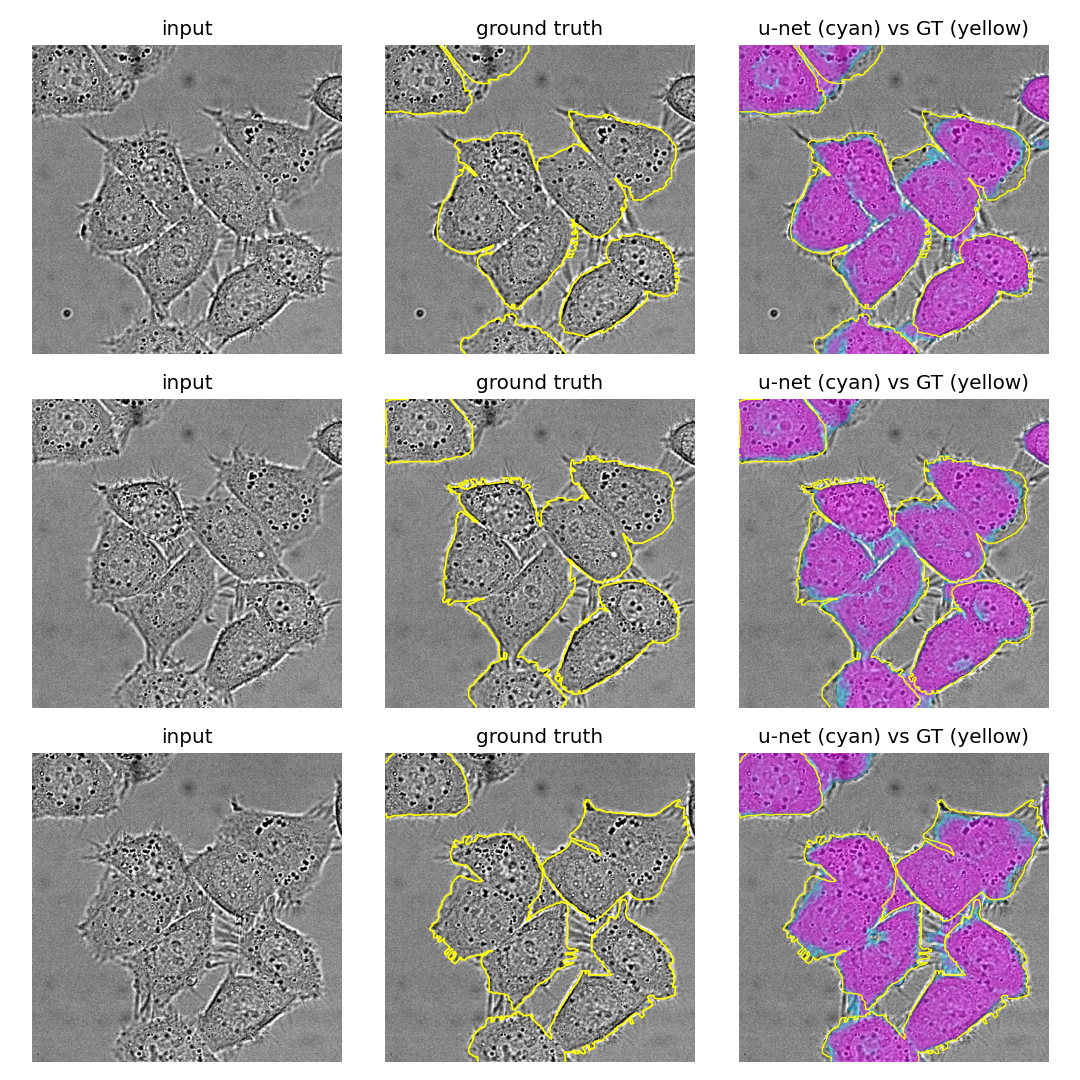

results/PhC-C2DH-U373_no_elastic_qualitative.png


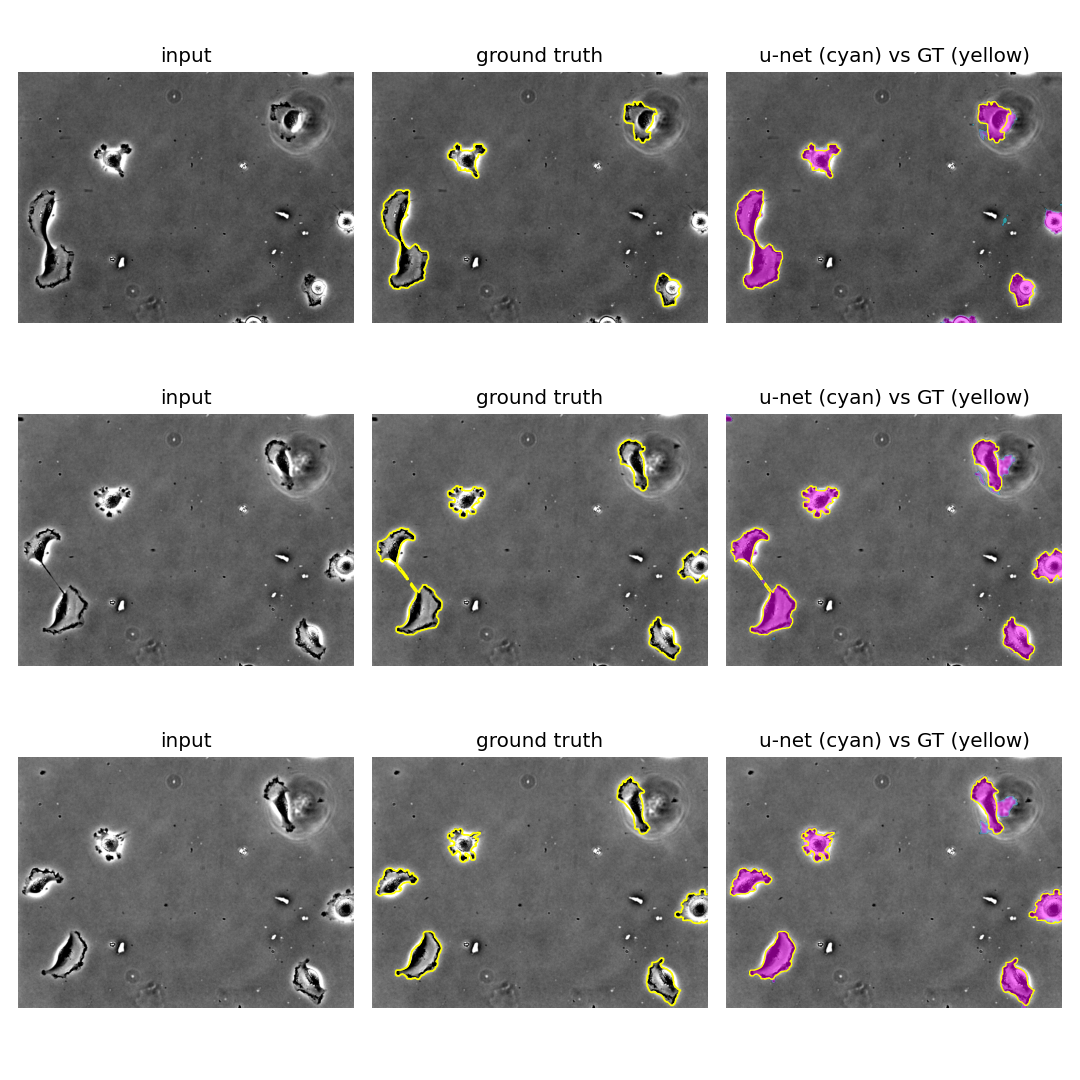

results/PhC-C2DH-U373_no_weight_qualitative.png


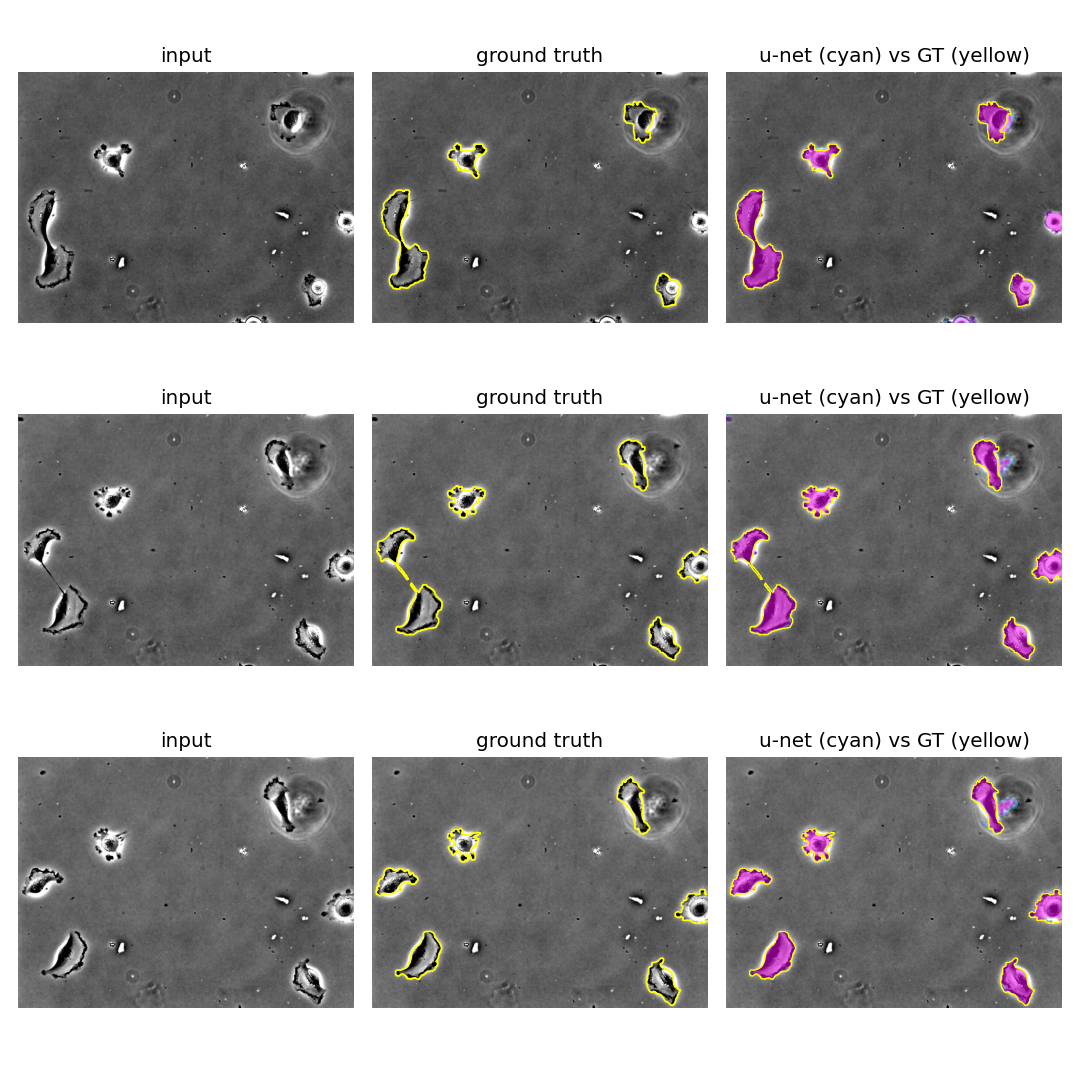

results/PhC-C2DH-U373_qualitative.png


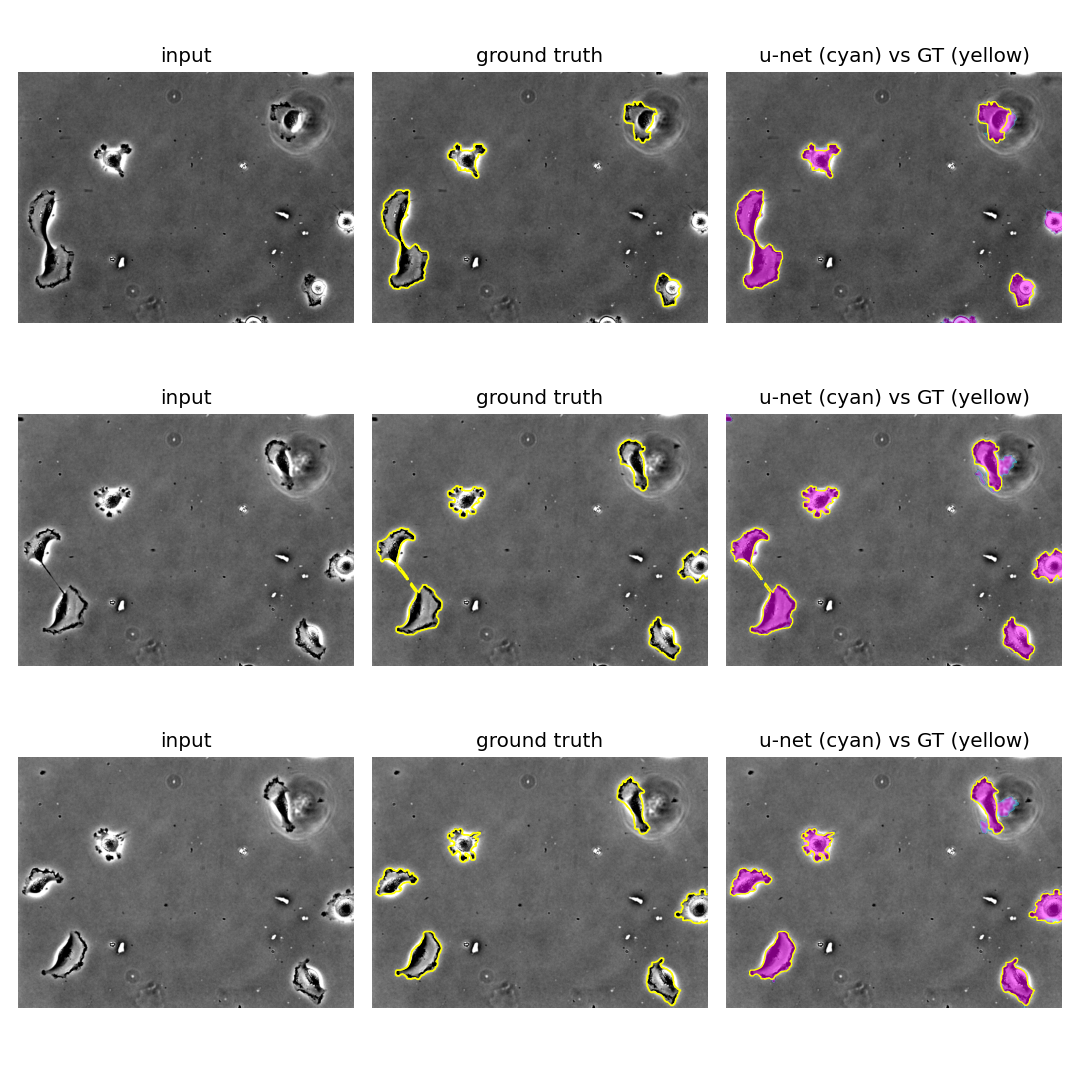

In [ ]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/*_qualitative.png')): print(f); display(Image(f))

In [ ]:
from google.colab import files
!zip -qr results.zip results/*.json results/*.png
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls -R results data 2>/dev/null | head -40

data:
DIC-C2DH-HeLa
DIC-C2DH-HeLa.zip
PhC-C2DH-U373
PhC-C2DH-U373.zip

data/DIC-C2DH-HeLa:
01
01_ERR_SEG
01_GT
01_ST
02
02_ERR_SEG
02_GT
02_ST

data/DIC-C2DH-HeLa/01:
t000.tif
t001.tif
t002.tif
t003.tif
t004.tif
t005.tif
t006.tif
t007.tif
t008.tif
t009.tif
t010.tif
t011.tif
t012.tif
t013.tif
t014.tif
t015.tif
t016.tif
t017.tif
t018.tif
t019.tif
t020.tif
t021.tif
t022.tif


In [ ]:
!ls data/PhC-C2DH-U373/01_GT data/PhC-C2DH-U373/01_GT/SEG | head -20

data/PhC-C2DH-U373/01_GT:
SEG
TRA

data/PhC-C2DH-U373/01_GT/SEG:
man_seg001.tif
man_seg005.tif
man_seg006.tif
man_seg007.tif
man_seg021.tif
man_seg049.tif
man_seg059.tif
man_seg067.tif
man_seg072.tif
man_seg075.tif
man_seg092.tif
man_seg096.tif
man_seg100.tif
man_seg102.tif
man_seg112.tif


In [15]:
!python train.py --dataset PhC-C2DH-U373 --iters 200 --eval_every 100 --tag test

annotated frames: 34 | train 15 | test 19 | split=seq
conv layers: 23 (paper: 23) | 572->388 | params 31.0M | device cuda amp=True
it   100 | loss 0.6188 | test SEG 0.4355 | fg-IoU 0.4970 | 14s
it   200 | loss 0.3935 | test SEG 0.5389 | fg-IoU 0.4611 | 26s
FINAL (8-fold flip/rot TTA) test SEG(IOU) 0.5363 | fg-IoU 0.4620
